## US sector momentum: holding the top 3 SPDR sector ETFs

**2270 Financial Modeling, NOVA SBE**

- Moodle group name: _to be added_
- Members: _to be added_
- GitHub repository: _to be added_
- Streamlit app: _to be added_

**Strategy in one paragraph.** At each month-end we rank the SPDR Select Sector ETFs by their past
12-month return, skipping the most recent month (12-1 momentum), and hold the top 3 with equal weight
(1/3 each) during the next month. The signal uses only prices up to month-end *t* and is applied to
returns in month *t+1*. The strategy is compared with SPY and with an equal-weight portfolio of all
available sectors.

This notebook reproduces every number, table and figure in the prospectus. It runs top to bottom in a
fresh Google Colab session; all data is downloaded through the Yahoo Finance API.

#### 0. Setup

Setup installs the one package Colab does not ship in a current version and holds
**every import used in the notebook**, so later cells never import anything.

In [133]:
#!pip install yfinance

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.size"] = 13   # text stays readable when a figure is scaled to page width

#### 1. Configuration

All assumptions sit in this one cell. The sample start and end dates are set explicitly. The strategy
parameters are the standard momentum settings, not values picked from the results; section 7 shows how
the results change when they are varied.

In [134]:
START_DATE = "1998-12-01"   # the nine original SPDR sector ETFs start trading on 22 Dec 1998
END_DATE = "2026-10-31"     # last full month before the valuation date (inclusive)

SECTOR_NAMES = {
    "XLB": "Materials",
    "XLE": "Energy",
    "XLF": "Financials",
    "XLI": "Industrials",
    "XLK": "Technology",
    "XLP": "Consumer Staples",
    "XLU": "Utilities",
    "XLV": "Health Care",
    "XLY": "Consumer Discretionary",
    "XLRE": "Real Estate",            # launched 2015, enters once it has enough history
    "XLC": "Communication Services",  # launched 2018, enters once it has enough history
}
SECTORS = list(SECTOR_NAMES)
BENCHMARK = "SPY"
RF_SERIES = "DGS3MO"   # FRED: 3-month Treasury constant-maturity yield, investment basis, % p.a.

# strategy parameters not tuned
N_HOLD = 3           # number of sectors held, equal weight
LOOKBACK = 12        # formation window in months
SKIP = 1             # most recent months excluded from the signal (12-1 momentum)
COST_BPS = 10        # one-way trading cost, basis points of traded value
PERIODS_PER_YEAR = 12

# scenarios for the later sections, fixed in advance
COST_LEVELS_BPS = [0, 10, 25, 50]
N_GRID = [2, 3, 4, 5]
LOOKBACK_GRID = [3, 6, 9, 12]
SPLIT_DATE = "2013-06-30"   # end of the first sub-period, about the middle of the sample
ROLLING_MONTHS = 36
SATELLITE_WEIGHTS = [0.10, 0.15, 0.20]   # share of the portfolio held in the strategy, the rest in SPY
FIGURE_DIR = "figures"      # PNG copies of the figures for the prospectus

#### 2. Data

- **Prices:** Yahoo Finance through the `yfinance` API. Daily adjusted close (adjusted for splits and
  dividends, so returns are total returns), in USD.
- **Frequency:** monthly. Each month is represented by the last available trading day.
- **Returns:** simple returns between consecutive month-ends. Unlike the log returns used in the
  lectures, simple returns add up across assets, so the portfolio return is the exact weighted
  average of the ETF returns.
- **Missing values:** nothing is dropped. XLRE and XLC are NaN before they exist, and the strategy
  only ranks the ETFs that have enough history (see the checks below).
- **Risk-free rate:** FRED series `DGS3MO`, the 3-month Treasury yield on an investment basis (official
  source, read from FRED's public CSV endpoint, no API key).

In [135]:
def download_prices(tickers, start, end):
    """Daily adjusted close from Yahoo Finance; `end` is inclusive."""
    end_exclusive = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    px = yf.download(tickers, start=start, end=end_exclusive, auto_adjust=True, progress=False)["Close"]
    return px[tickers]


def download_fred(series_id, start, end):
    """Daily FRED series from the public CSV endpoint (no API key needed); `end` is inclusive."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    series = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    return series.loc[start:end]


daily = download_prices(SECTORS + [BENCHMARK], START_DATE, END_DATE)
yield_daily = download_fred(RF_SERIES, START_DATE, END_DATE)

# month-end prices and simple monthly returns (NaN before an ETF exists)
prices = daily.resample("ME").last()
returns = prices / prices.shift(1) - 1

# monthly risk-free return, lagged one month (yield at end of t-1 is earned during t)
yield_month_end = yield_daily.resample("ME").last().reindex(prices.index)
rf = ((1 + yield_month_end / 100) ** (1 / 12) - 1).shift(1).rename("rf")

#### Data checks / EDA

Shape: (335, 12)
Start: December 1998, End: October 2026
Missing values
 Ticker
XLB       0
XLE       0
XLF       0
XLI       0
XLK       0
XLP       0
XLU       0
XLV       0
XLY       0
XLRE    202
XLC     234
SPY       0
dtype: int64


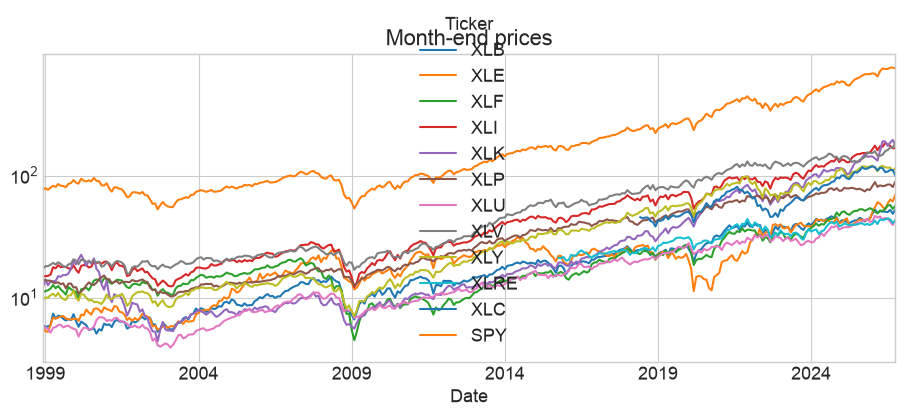

In [136]:
print("Shape:", prices.shape)
print(f"Start: {prices.index[0]:%B %Y}, End: {prices.index[-1]:%B %Y}")
print("Missing values\n", prices.isna().sum())
prices.plot(title="Month-end prices", logy=True, figsize=(11, 4));

Month-end prices and monthly returns. The first return is NaN, because a return needs two prices.

In [137]:
prices.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,XLRE,XLC,SPY
Date,,,,,,,,,,,,
1998-12-31,5.968431,5.680913,11.144693,15.148267,12.109813,14.140615,5.831352,17.296885,9.580882,NaN,NaN,76.257217
1999-01-31,5.747218,5.308270,11.337869,14.984447,14.035324,13.953493,5.686697,18.128468,10.073680,NaN,NaN,78.943367
1999-02-28,5.836550,5.262642,11.516180,15.119351,12.643391,13.807036,5.529987,18.149254,10.010643,NaN,NaN,76.411789
1999-03-31,5.941551,6.006630,11.889435,15.436928,13.582939,13.790672,5.181117,18.627426,10.497638,NaN,NaN,79.580414
1999-04-30,7.409862,6.895791,12.723769,17.758270,13.664133,13.309795,5.681634,19.292683,10.772985,NaN,NaN,82.602425


In [138]:
returns.head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,XLRE,XLC,SPY
Date,,,,,,,,,,,,
1998-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-01-31,-0.037064,-0.065596,0.017333,-0.010814,0.159004,-0.013233,-0.024806,0.048077,0.051436,NaN,NaN,0.035225
1999-02-28,0.015544,-0.008596,0.015727,0.009003,-0.099174,-0.010496,-0.027557,0.001147,-0.006258,NaN,NaN,-0.032068
1999-03-31,0.017990,0.141372,0.032411,0.021005,0.074311,-0.001185,-0.063087,0.026347,0.048648,NaN,NaN,0.041468
1999-04-30,0.247126,0.148030,0.070174,0.150376,0.005978,-0.034870,0.096604,0.035714,0.026229,NaN,NaN,0.037974


In [139]:
returns.describe()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,XLRE,XLC,SPY
count,334.000000,334.000000,334.000000,334.000000,334.000000,334.000000,334.000000,334.000000,334.000000,132.000000,100.000000,334.000000
mean,0.008333,0.010169,0.006729,0.008673,0.010358,0.006200,0.007013,0.007965,0.008995,0.006607,0.009378,0.007836
std,0.059898,0.072407,0.060373,0.053815,0.066942,0.036343,0.044176,0.041157,0.055265,0.049137,0.055212,0.043374
min,-0.223952,-0.343710,-0.261981,-0.186260,-0.249062,-0.126087,-0.147216,-0.144792,-0.176344,-0.151066,-0.141320,-0.165187
25%,-0.029532,-0.028201,-0.025549,-0.021372,-0.025267,-0.013389,-0.018979,-0.018665,-0.019894,-0.021955,-0.021795,-0.016120
50%,0.009468,0.011482,0.012274,0.009678,0.015814,0.008751,0.012210,0.010675,0.010761,0.010403,0.016259,0.012696
75%,0.043537,0.049238,0.041199,0.039249,0.049271,0.029154,0.036421,0.032923,0.044140,0.034253,0.044064,0.035266
max,0.247126,0.307639,0.217934,0.180684,0.247676,0.109429,0.132144,0.125875,0.188826,0.124773,0.147739,0.126983


The risk-free rate is lagged one month, so the first month has no rate. Every later month must have one.

In [140]:
assert rf.iloc[1:].notna().all(), "missing risk-free rate after the first month"
rf.describe()

count    334.000000
mean       0.001720
std        0.001651
min        0.000000
25%        0.000102
50%        0.001283
75%        0.003326
max        0.005167
Name: rf, dtype: float64

#### 3. Signal and portfolio

**Signal.** For each sector ETF, the 12-1 momentum signal at month-end *t* is its return from month-end
*t*-12 to month-end *t*-1, so the latest month is skipped. The signal needs 13 month-end prices and is
NaN before that: XLRE and XLC join the ranking automatically once they have a signal, and no missing
value is filled. SPY is only the benchmark and is never ranked.

**Portfolio.** The three ETFs with the highest signal get a weight of 1/3 each, all others get 0. The
portfolio is rebalanced to these target weights every month(end).

**Timing.** The weights decided at month-end *t* earn the return of month *t*+1 (`weights.shift(1)` in
`run_strategy`). Trading at the month-end close that produced the signal is the standard academic lag;
section 7 repeats the backtest with one more month of delay.

**Turnover and costs.** Between rebalances the weights drift with the ETF returns. Turnover is the value
traded to get back to the target weights (buys plus sells) as a share of portfolio value. The net
return is the gross return minus turnover times the one-way cost.

In [141]:
def momentum_signal(prices, lookback, skip):
    """Return from month-end t-lookback to month-end t-skip, known at month-end t."""
    return prices.shift(skip) / prices.shift(lookback) - 1


def top_n_weights(signal, n):
    """Weight 1/n on the n ETFs with the highest signal, 0 elsewhere; NaN while fewer than n have a signal."""
    rank = signal.rank(axis=1, ascending=False, method="first")
    weights = (rank <= n) / n
    enough = signal.notna().sum(axis=1) >= n
    return weights.loc[enough].reindex(signal.index)


def equal_weights(signal):
    """Weight 1/k on each of the k ETFs that have a signal (the ranking universe); NaN while none has."""
    eligible = signal.notna()
    return eligible.div(eligible.sum(axis=1), axis=0)


def run_strategy(returns, weights):
    """Gross monthly return and turnover of a portfolio rebalanced to `weights` at every month-end.

    Weights set at month-end t are held during t+1. Before each rebalance the previous weights have
    drifted with the returns; turnover is the traded value (buys + sells) as a share of the portfolio.
    The first month builds the portfolio from cash, so its turnover is 1.
    """
    held = weights.shift(1).dropna(how="all")
    r = returns.loc[held.index, held.columns]
    assert not (held.gt(0) & r.isna()).any().any(), "a held ETF has no return"
    r = r.fillna(0)
    gross = (held * r).sum(axis=1)
    drifted = (held * (1 + r)).div(1 + gross, axis=0)
    turnover = (held - drifted.shift(1).fillna(0)).abs().sum(axis=1)
    return gross.rename("gross"), turnover.rename("turnover")


def net_returns(gross, turnover, cost_bps):
    """Gross return minus the one-way cost on the traded value."""
    return gross - turnover * cost_bps / 10_000

In [142]:
signal = momentum_signal(prices[SECTORS], LOOKBACK, SKIP)
weights = top_n_weights(signal, N_HOLD)
gross, turnover = run_strategy(returns, weights)

print(f"First signal: {weights.dropna(how='all').index[0]:%B %Y}")
print(f"Returns earned: {gross.index[0]:%B %Y} to {gross.index[-1]:%B %Y} ({len(gross)} months)")
print(f"Average annual turnover: {PERIODS_PER_YEAR * turnover.mean():.1f} times the portfolio value (buys + sells)")

First signal: December 1999
Returns earned: January 2000 to October 2026 (322 months)
Average annual turnover: 5.4 times the portfolio value (buys + sells)


The holdings chosen at the last month-end of the sample, the ones the strategy would hold in the next
month:

In [143]:
latest = weights.iloc[-1]
top = latest[latest > 0].index
pd.DataFrame({"name": pd.Series(SECTOR_NAMES)[top], "12-1 return": signal.iloc[-1][top], "weight": latest[top]})

,name,12-1 return,weight
XLE,Energy,0.435458,0.333333
XLK,Technology,0.308727,0.333333
XLV,Health Care,0.187067,0.333333


#### 4. Benchmarks

- **SPY** is the market benchmark. It is a buy-and-hold position and pays no trading costs. Alpha,
  beta and the information ratio are measured against it.
- **Equal-weight sectors** holds all ETFs that are in the ranking universe with weight 1/k each,
  rebalanced every month. It has the same universe and the same cost assumption as the strategy, so
  the difference between the two isolates the effect of the ranking.

The table below collects the monthly return series used in the rest of the notebook. "Net" means after
trading costs at `COST_BPS`.

In [144]:
ew_weights = equal_weights(signal)
ew_gross, ew_turnover = run_strategy(returns, ew_weights)
assert gross.index.equals(ew_gross.index)

NET, GROSS, EW = "Strategy (net)", "Strategy (gross)", "Equal-weight sectors (net)"
monthly = pd.DataFrame({
    NET: net_returns(gross, turnover, COST_BPS),
    GROSS: gross,
    EW: net_returns(ew_gross, ew_turnover, COST_BPS),
    BENCHMARK: returns[BENCHMARK].loc[gross.index],
})
assert monthly.notna().all().all(), "missing return in the evaluation sample"
print(f"Average annual turnover: strategy {PERIODS_PER_YEAR * turnover.mean():.1f}, "
      f"equal-weight sectors {PERIODS_PER_YEAR * ew_turnover.mean():.1f}")
monthly.head()

Average annual turnover: strategy 5.4, equal-weight sectors 0.4


,Strategy (net),Strategy (gross),Equal-weight sectors (net),SPY
Date,,,,
2000-01-31,-0.046069,-0.045069,-0.050506,-0.049788
2000-02-29,-0.013256,-0.012578,-0.062223,-0.015226
2000-03-31,0.115154,0.115841,0.112101,0.096915
2000-04-30,-0.030795,-0.030776,-0.003356,-0.035120
2000-05-31,-0.005161,-0.004452,-0.001330,-0.015723


#### 5. Performance

All measures use monthly returns and are annualized as follows.

- **Average return:** monthly mean × 12 (arithmetic, as in the lectures). The CAGR is the geometric alternative.
- **Volatility:** monthly standard deviation × √12.
- **Sharpe ratio:** (12 × mean excess return) / (√12 × standard deviation of the excess return). Excess
  return is the return minus the risk-free return of the same month.
- **Alpha and beta:** OLS regression of the strategy's monthly excess return on the benchmark's monthly
  excess return. Alpha is the intercept × 12, in % p.a., shown with its t-statistic. Beta is the slope and
  is not annualized.
- **Information ratio:** (12 × mean active return) / (√12 × tracking error), where the active return is
  the strategy return minus the benchmark return.
- **Maximum drawdown:** the largest fall of the cumulative return from a previous peak.

The risk-free rate is DGS3MO, converted to a monthly return and lagged one month (section 2). Alpha,
beta and the information ratio are shown only for series that differ from their benchmark.

In [145]:
def sharpe_ratio(r, rf):
    """Annualized Sharpe ratio of monthly returns `r`."""
    excess = r - rf.loc[r.index]
    return PERIODS_PER_YEAR * excess.mean() / (np.sqrt(PERIODS_PER_YEAR) * excess.std())


def alpha_beta(r, bench, rf):
    """OLS of excess return on benchmark excess return: annualized alpha (decimal), beta, t-stat of alpha."""
    rf = rf.loc[r.index]
    assert rf.notna().all(), "missing risk-free rate"
    fit = sm.OLS(r - rf, sm.add_constant(bench.loc[r.index] - rf)).fit()
    return PERIODS_PER_YEAR * fit.params.iloc[0], fit.params.iloc[1], fit.tvalues.iloc[0]


def wealth_index(rets):
    """Growth of 1; a starting value of 1 is added one month before the first return."""
    wealth = (1 + rets).cumprod()
    wealth.loc[rets.index[0] - pd.offsets.MonthEnd(1)] = 1.0
    return wealth.sort_index()


def drawdowns(rets):
    """Fall from the previous peak of the cumulative return, as a negative fraction."""
    wealth = wealth_index(rets)
    return wealth / wealth.cummax() - 1


def performance_table(rets, rf, benchmark):
    """Performance measures, one column per series in `rets`, measured against column `benchmark`."""
    k = PERIODS_PER_YEAR
    table = {}
    for name, r in rets.items():
        if name == benchmark:
            alpha, beta, t_alpha, info = np.nan, np.nan, np.nan, np.nan
        else:
            alpha, beta, t_alpha = alpha_beta(r, rets[benchmark], rf)
            active = r - rets[benchmark]
            info = k * active.mean() / (np.sqrt(k) * active.std())
        table[name] = {
            "Average return (% p.a.)": 100 * k * r.mean(),
            "CAGR (% p.a.)": 100 * ((1 + r).prod() ** (k / len(r)) - 1),
            "Volatility (% p.a.)": 100 * np.sqrt(k) * r.std(),
            "Sharpe ratio": sharpe_ratio(r, rf),
            "Alpha (% p.a.)": 100 * alpha,
            "Alpha t-stat": t_alpha,
            "Beta": beta,
            "Information ratio": info,
            "Max drawdown (%)": 100 * drawdowns(r).min(),
        }
    return pd.DataFrame(table)


def show(table, precision=2):
    """Format a table as text with a dash for undefined entries."""
    def fmt(x):
        if isinstance(x, str):
            return x
        if pd.isna(x):
            return "–"
        return f"{x:d}" if isinstance(x, (int, np.integer)) else f"{x:.{precision}f}"
    return table.map(fmt)

In [146]:
print(f"Table 1: performance {monthly.index[0]:%b %Y} to {monthly.index[-1]:%b %Y}, "
      f"benchmark {BENCHMARK}, costs {COST_BPS} bp one-way")
table1 = performance_table(monthly[[NET, GROSS, BENCHMARK, EW]], rf, BENCHMARK)
show(table1)

Table 1: performance Jan 2000 to Oct 2026, benchmark SPY, costs 10 bp one-way


,Strategy (net),Strategy (gross),SPY,Equal-weight sectors (net)
Average return (% p.a.),9.71,10.25,9.03,9.42
CAGR (% p.a.),8.91,9.50,8.17,8.67
Volatility (% p.a.),15.07,15.07,15.11,14.62
Sharpe ratio,0.51,0.55,0.47,0.51
Alpha (% p.a.),1.69,2.23,–,0.88
Alpha t-stat,1.12,1.48,–,1.12
Beta,0.86,0.86,–,0.93
Information ratio,0.08,0.15,–,0.09
Max drawdown (%),-41.43,-41.21,-50.78,-49.16


In [147]:
print("Table 2: strategy against the equal-weight sectors portfolio (benchmark = equal-weight sectors)")
table2 = performance_table(monthly[[NET, EW]], rf, EW)
show(table2)

Table 2: strategy against the equal-weight sectors portfolio (benchmark = equal-weight sectors)


,Strategy (net),Equal-weight sectors (net)
Average return (% p.a.),9.71,9.42
CAGR (% p.a.),8.91,8.67
Volatility (% p.a.),15.07,14.62
Sharpe ratio,0.51,0.51
Alpha (% p.a.),1.02,–
Alpha t-stat,0.71,–
Beta,0.90,–
Information ratio,0.04,–
Max drawdown (%),-41.43,-49.16


Charts use one style: black and greys with different line types, and one accent colour for the
strategy so that they stay readable in print. Every chart is also saved as a PNG in `FIGURE_DIR`.

In [148]:
ACCENT = "#80241E"   # the one accent colour, used for the strategy only
STYLES = {
    NET: dict(color=ACCENT, linestyle="-", linewidth=2.0),
    GROSS: dict(color=ACCENT, linestyle=":", linewidth=1.5),
    EW: dict(color="#7F7F7F", linestyle="-.", linewidth=1.5),
    BENCHMARK: dict(color="black", linestyle="--", linewidth=1.5),
}


def style_axes(ax):
    """Black spines and a dashed light-grey horizontal grid only."""
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
    ax.grid(False)
    ax.grid(axis="y", linestyle="--", color="lightgrey")
    ax.set_axisbelow(True)


def save_figure(fig, name):
    Path(FIGURE_DIR).mkdir(exist_ok=True)
    fig.savefig(Path(FIGURE_DIR) / f"{name}.png", dpi=300, bbox_inches="tight")


def plot_cumulative(rets, styles, name):
    """Growth of 1 on a log axis; every series starts at 1."""
    wealth = wealth_index(rets)
    fig, ax = plt.subplots(figsize=(11, 4))
    for column in wealth:
        ax.plot(wealth.index, wealth[column], label=column, **styles[column])
    ax.set_yscale("log")
    low, high = wealth.min().min() * 0.9, wealth.max().max() * 1.1
    ticks = [t for t in (0.5, 1, 2, 3, 5, 10, 20, 30, 50, 100) if low <= t <= high]
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:g}" for t in ticks])
    ax.minorticks_off()
    ax.margins(x=0)
    ax.set_ylabel("Value of 1 invested (log scale)")
    ax.legend(frameon=False, loc="upper left")
    style_axes(ax)
    save_figure(fig, name)
    plt.show()


def plot_drawdowns(rets, styles, name):
    """Drawdown from the previous peak, in percent."""
    dd = 100 * drawdowns(rets)
    fig, ax = plt.subplots(figsize=(11, 4))
    for column in dd:
        ax.plot(dd.index, dd[column], label=column, **styles[column])
    ax.margins(x=0)
    ax.set_ylabel("Drawdown from previous peak (%)")
    ax.legend(frameon=False, loc="lower left")
    style_axes(ax)
    save_figure(fig, name)
    plt.show()

Figure 1: cumulative performance, growth of 1


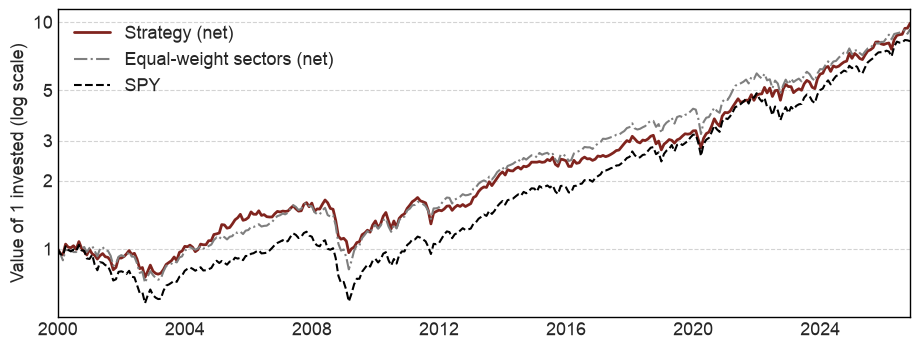

In [149]:
print("Figure 1: cumulative performance, growth of 1")
plot_cumulative(monthly[[NET, EW, BENCHMARK]], STYLES, "fig1_cumulative")

Figure 2: drawdowns


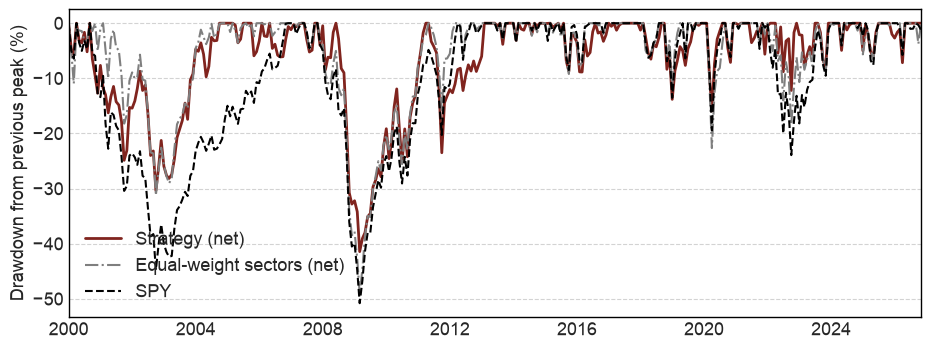

In [150]:
print("Figure 2: drawdowns")
plot_drawdowns(monthly[[NET, EW, BENCHMARK]], STYLES, "fig2_drawdowns")

Two more views of the same net returns: the return in every calendar year, and a rolling window of
`ROLLING_MONTHS` months for the active return against SPY and for beta.

In [151]:
def plot_calendar_years(rets, colors, name):
    """Return of every calendar year as grouped bars; a partial last year is marked with *."""
    yearly = 100 * ((1 + rets).groupby(rets.index.year).prod() - 1)
    x = np.arange(len(yearly))
    width = 0.4
    fig, ax = plt.subplots(figsize=(11, 4))
    for k, column in enumerate(yearly):
        ax.bar(x + (k - (yearly.shape[1] - 1) / 2) * width, yearly[column], width, label=column, color=colors[column])
    labels = [str(year) for year in yearly.index]
    if rets.index[-1].month != 12:
        labels[-1] += "*"
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.margins(x=0.01)
    ax.set_ylabel("Return in the year (%)")
    ax.legend(frameon=False, loc="lower left")
    style_axes(ax)
    save_figure(fig, name)
    plt.show()
    return yearly


def plot_rolling(strategy, bench, rf, window, name):
    """Rolling average active return against the benchmark (% p.a.) and rolling beta."""
    active = 100 * PERIODS_PER_YEAR * (strategy - bench).rolling(window).mean()
    excess, bench_excess = strategy - rf.loc[strategy.index], bench - rf.loc[bench.index]
    beta = excess.rolling(window).cov(bench_excess) / bench_excess.rolling(window).var()
    fig, (ax_active, ax_beta) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
    ax_active.plot(active.index, active, color=ACCENT, linewidth=2.0)
    ax_active.axhline(0, color="black", linewidth=0.8)
    ax_active.set_ylabel(f"Active return vs {bench.name} (% p.a.)")
    ax_beta.plot(beta.index, beta, color=ACCENT, linewidth=2.0)
    ax_beta.axhline(1, color="black", linewidth=0.8)
    ax_beta.set_ylabel(f"Beta vs {bench.name}")
    for ax in (ax_active, ax_beta):
        ax.margins(x=0)
        style_axes(ax)
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()

Figure 3: return in each calendar year (* year to date)


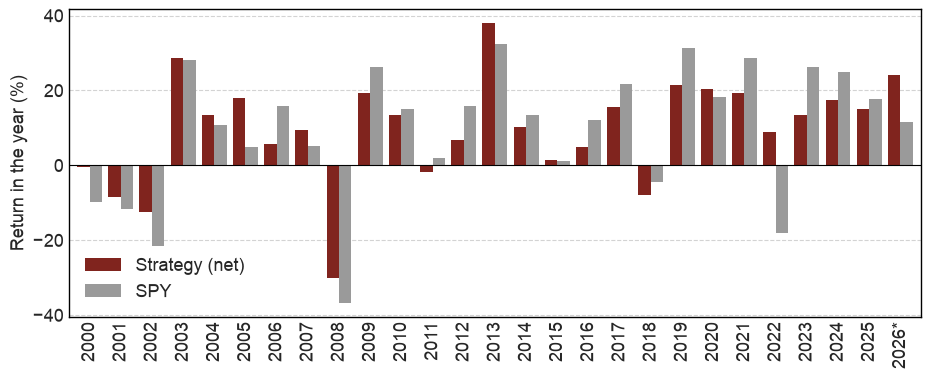

The strategy beat SPY in 13 of 27 calendar years


In [152]:
print("Figure 3: return in each calendar year (* year to date)")
yearly = plot_calendar_years(monthly[[NET, BENCHMARK]], {NET: ACCENT, BENCHMARK: "#9A9A9A"}, "fig3_calendar")
beats = yearly[NET] > yearly[BENCHMARK]
print(f"The strategy beat {BENCHMARK} in {beats.sum()} of {len(beats)} calendar years")

Figure 4: rolling 36-month active return and beta against SPY


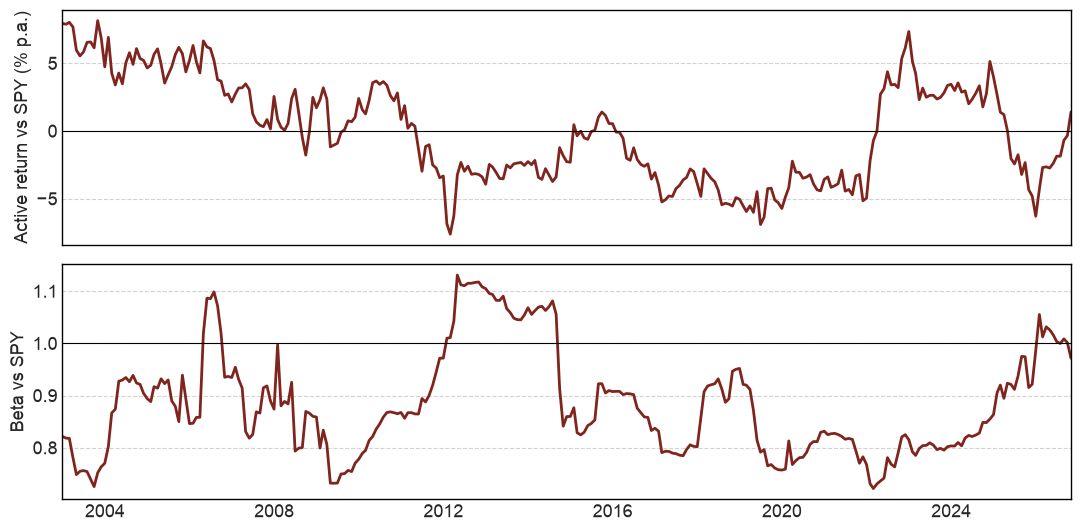

In [153]:
print(f"Figure 4: rolling {ROLLING_MONTHS}-month active return and beta against {BENCHMARK}")
plot_rolling(monthly[NET], monthly[BENCHMARK], rf, ROLLING_MONTHS, "fig4_rolling")

#### 6. Transaction costs

The strategy rotates sectors, so costs matter. The one-way cost is charged on the traded value (buys
plus sells) of every rebalance, at the four levels in `COST_LEVELS_BPS`. SPY is the buy-and-hold
benchmark without costs.

Table 3 first compares the strategy before and after costs since the start of the backtest. ETF
expense ratios are already in the adjusted prices, so "before costs" means before trading costs.

In [154]:
inception = monthly[[GROSS, NET, BENCHMARK]].rename(columns={
    GROSS: "Strategy before costs", NET: f"Strategy after costs ({COST_BPS} bp)"})
table3 = performance_table(inception, rf, BENCHMARK)
table3.loc["Cumulative return (%)"] = 100 * ((1 + inception).prod() - 1)

print(f"Table 3: since inception ({monthly.index[0]:%b %Y} to {monthly.index[-1]:%b %Y}), before and after costs")
show(table3.loc[["Cumulative return (%)"] + list(table3.index[:-1])])

Table 3: since inception (Jan 2000 to Oct 2026), before and after costs


,Strategy before costs,Strategy after costs (10 bp),SPY
Cumulative return (%),1042.75,888.46,723.17
Average return (% p.a.),10.25,9.71,9.03
CAGR (% p.a.),9.50,8.91,8.17
Volatility (% p.a.),15.07,15.07,15.11
Sharpe ratio,0.55,0.51,0.47
Alpha (% p.a.),2.23,1.69,–
Alpha t-stat,1.48,1.12,–
Beta,0.86,0.86,–
Information ratio,0.15,0.08,–
Max drawdown (%),-41.21,-41.43,-50.78


In [155]:
cost_returns = pd.DataFrame({f"{bps} bp": net_returns(gross, turnover, bps) for bps in COST_LEVELS_BPS})
cost_returns[BENCHMARK] = monthly[BENCHMARK]
rows = ["Average return (% p.a.)", "Sharpe ratio", "Alpha (% p.a.)", "Alpha t-stat", "Information ratio"]

print("Table 4: strategy net of costs, by one-way cost level")
table3 = performance_table(cost_returns, rf, BENCHMARK).loc[rows]
show(table3)

Table 4: strategy net of costs, by one-way cost level


,0 bp,10 bp,25 bp,50 bp,SPY
Average return (% p.a.),10.25,9.71,8.89,7.53,9.03
Sharpe ratio,0.55,0.51,0.46,0.37,0.47
Alpha (% p.a.),2.23,1.69,0.87,-0.48,–
Alpha t-stat,1.48,1.12,0.58,-0.32,–
Information ratio,0.15,0.08,-0.02,-0.19,–


In [156]:
annual_turnover = PERIODS_PER_YEAR * turnover.mean()
breakeven_bps = (gross.mean() - monthly[BENCHMARK].mean()) / turnover.mean() * 10_000
print(f"Average annual turnover: {annual_turnover:.1f} times the portfolio value (buys + sells)")
print(f"Cost drag at {COST_BPS} bp: {100 * annual_turnover * COST_BPS / 10_000:.2f}% p.a.")
print(f"One-way cost at which the average return falls to SPY's: {breakeven_bps:.0f} bp")

Average annual turnover: 5.4 times the portfolio value (buys + sells)
Cost drag at 10 bp: 0.54% p.a.
One-way cost at which the average return falls to SPY's: 22 bp


Figure 5: cumulative performance of the strategy net of costs


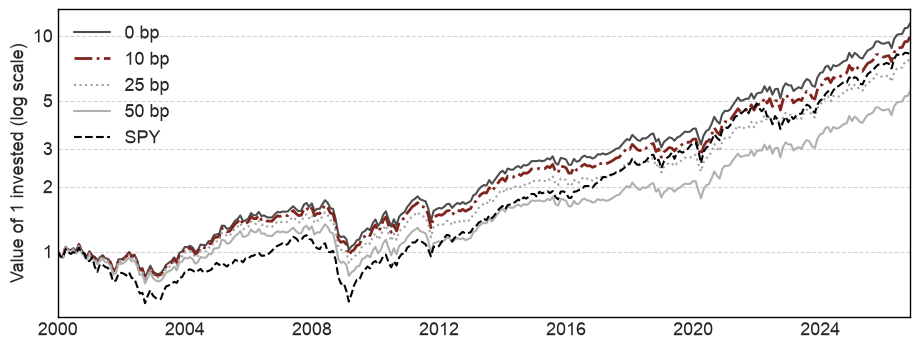

In [157]:
cost_styles = {
    label: dict(color=ACCENT if bps == COST_BPS else shade, linestyle=line, linewidth=2.0 if bps == COST_BPS else 1.5)
    for (label, bps), shade, line in zip(
        [(f"{b} bp", b) for b in COST_LEVELS_BPS], ["#4D4D4D", "#808080", "#A0A0A0", "#B0B0B0"], ["-", "-.", ":", "-"])
}
cost_styles[BENCHMARK] = STYLES[BENCHMARK]

print("Figure 5: cumulative performance of the strategy net of costs")
plot_cumulative(cost_returns, cost_styles, "fig5_costs")

#### 7. Robustness

The standard 12-1 signal with three holdings is the strategy. The checks below show how the results
change when the choices are varied. They are not used to pick better parameters.

All variants are net of `COST_BPS` and are evaluated on the same months, from the second month of the
sample, so that the variant with an extra month of delay is comparable. The numbers for the baseline
therefore differ slightly from Table 1.

Figure 6: Sharpe ratio and alpha against SPY (% p.a.) for different numbers of ETFs and lookbacks


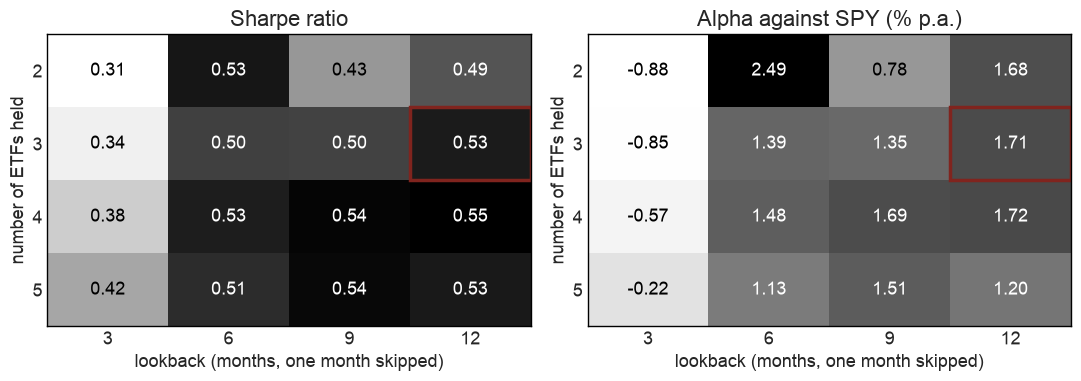

SPY Sharpe ratio on the same months: 0.48
11 of 16 cells have a higher Sharpe ratio than SPY, 12 of 16 have positive alpha


In [158]:
def variant_returns(n, lookback, skip, extra_lag=0, cost_bps=COST_BPS):
    """Net monthly returns of the strategy with other parameters; `extra_lag` delays trading by whole months."""
    sig = momentum_signal(prices[SECTORS], lookback, skip)
    w = top_n_weights(sig, n).shift(extra_lag)
    g, t = run_strategy(returns, w)
    return net_returns(g, t, cost_bps)


def plot_heatmaps(grids, default, name):
    """Heatmaps side by side; rows: number of ETFs held, columns: lookback. The default cell is outlined."""
    fig, axes = plt.subplots(1, len(grids), figsize=(11, 4))
    for ax, (title, grid) in zip(axes, grids.items()):
        values = grid.to_numpy(dtype=float)
        middle = (values.min() + values.max()) / 2
        ax.imshow(values, cmap="Greys", aspect="auto")
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                        color="white" if values[i, j] > middle else "black")
        row, col = grid.index.get_loc(default[0]), grid.columns.get_loc(default[1])
        ax.add_patch(plt.Rectangle((col - 0.5, row - 0.5), 1, 1, fill=False, edgecolor=ACCENT, linewidth=2.5))
        ax.set_xticks(range(len(grid.columns)))
        ax.set_xticklabels(grid.columns)
        ax.set_yticks(range(len(grid.index)))
        ax.set_yticklabels(grid.index)
        ax.set_xlabel("lookback (months, one month skipped)")
        ax.set_ylabel("number of ETFs held")
        ax.set_title(title)
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
    fig.tight_layout()
    save_figure(fig, name)
    plt.show()


common = monthly.index[1:]
spy_common = monthly.loc[common, BENCHMARK]

sharpe_grid = pd.DataFrame({
    lb: {n: sharpe_ratio(variant_returns(n, lb, SKIP).loc[common], rf) for n in N_GRID} for lb in LOOKBACK_GRID})
alpha_grid = pd.DataFrame({
    lb: {n: 100 * alpha_beta(variant_returns(n, lb, SKIP).loc[common], spy_common, rf)[0] for n in N_GRID}
    for lb in LOOKBACK_GRID})

print("Figure 6: Sharpe ratio and alpha against SPY (% p.a.) for different numbers of ETFs and lookbacks")
plot_heatmaps({"Sharpe ratio": sharpe_grid, "Alpha against SPY (% p.a.)": alpha_grid}, (N_HOLD, LOOKBACK), "fig6_grid")

spy_sharpe = sharpe_ratio(spy_common, rf)
print(f"SPY Sharpe ratio on the same months: {spy_sharpe:.2f}")
print(f"{(sharpe_grid.to_numpy() > spy_sharpe).sum()} of {sharpe_grid.size} cells have a higher Sharpe ratio than SPY, "
      f"{(alpha_grid.to_numpy() > 0).sum()} of {alpha_grid.size} have positive alpha")

In [159]:
variants = pd.DataFrame({
    f"{LOOKBACK}-{SKIP} (baseline)": variant_returns(N_HOLD, LOOKBACK, SKIP),
    f"{LOOKBACK}-0 (no skipped month)": variant_returns(N_HOLD, LOOKBACK, 0),
    f"{LOOKBACK}-{SKIP}, trades one month later": variant_returns(N_HOLD, LOOKBACK, SKIP, extra_lag=1),
}).loc[common]
variants[BENCHMARK] = spy_common

print("Table 5: skipped month and execution delay (net of costs)")
table4 = performance_table(variants, rf, BENCHMARK)
show(table4)

Table 5: skipped month and execution delay (net of costs)


,12-1 (baseline),12-0 (no skipped month),"12-1, trades one month later",SPY
Average return (% p.a.),9.91,9.71,11.02,9.24
CAGR (% p.a.),9.13,8.99,10.24,8.41
Volatility (% p.a.),15.06,14.59,15.63,15.09
Sharpe ratio,0.53,0.53,0.58,0.48
Alpha (% p.a.),1.71,1.77,2.58,–
Alpha t-stat,1.13,1.17,1.65,–
Beta,0.86,0.82,0.89,–
Information ratio,0.08,0.06,0.22,–
Max drawdown (%),-41.43,-39.18,-43.27,-50.78


In [160]:
split = pd.Timestamp(SPLIT_DATE)
parts = {
    f"{monthly.index[0]:%Y-%m} to {split:%Y-%m}": monthly[monthly.index <= split],
    f"after {split:%Y-%m}": monthly[monthly.index > split],
}
rows = ["Average return (% p.a.)", "Volatility (% p.a.)", "Sharpe ratio", "Alpha (% p.a.)", "Beta",
        "Information ratio", "Max drawdown (%)"]

print("Table 6: sub-periods (net of costs; alpha, beta and information ratio against SPY)")
table5 = pd.concat({label: performance_table(part[[NET, EW, BENCHMARK]], rf, BENCHMARK).loc[rows]
                    for label, part in parts.items()}, axis=1)
show(table5)

Table 6: sub-periods (net of costs; alpha, beta and information ratio against SPY)


2000-01 to 2013-06                                     \
                            Strategy (net) Equal-weight sectors (net)     SPY   
Average return (% p.a.)               5.93                       6.26    3.73   
Volatility (% p.a.)                  16.11                      15.41   15.74   
Sharpe ratio                          0.24                       0.27    0.11   
Alpha (% p.a.)                        2.42                       2.61       –   
Beta                                  0.87                       0.95       –   
Information ratio                     0.25                       0.68       –   
Max drawdown (%)                    -41.43                     -49.16  -50.78   

                         after 2013-06                                     
                        Strategy (net) Equal-weight sectors (net)     SPY  
Average return (% p.a.)          13.53                      12.61   14.39  
Volatility (% p.a.)              13.91                      13.77   14.32  
Sharpe ratio                      0.84                       0.78    0.87  
Alpha (% p.a.)                    1.10                      -0.69       –  
Beta                              0.84                       0.91       –  
Information ratio                -0.12                      -0.39       –  
Max drawdown (%)                -15.94                     -22.65  -23.93

#### 8. Use as a satellite

The target client keeps a core S&P 500 position and holds the strategy as a satellite of 10 to 20% of the
portfolio. The blends below put the weights in `SATELLITE_WEIGHTS` in the strategy (net of costs) and the
rest in SPY, rebalanced every month. The cost of that second rebalance between two ETFs is ignored.
Alpha and information ratio are measured against SPY only, the core position.

In [161]:
blend_returns = {"SPY only": monthly[BENCHMARK]}
for w in SATELLITE_WEIGHTS:
    blend_returns[f"{1 - w:.0%} SPY + {w:.0%} strategy"] = (1 - w) * monthly[BENCHMARK] + w * monthly[NET]
blend_returns = pd.DataFrame(blend_returns)

rows = ["Average return (% p.a.)", "Volatility (% p.a.)", "Sharpe ratio", "Max drawdown (%)", "Alpha (% p.a.)", "Information ratio"]
print("Table 7: SPY alone and with the strategy as a satellite")
table7 = performance_table(blend_returns, rf, "SPY only").loc[rows]
table7.loc["Tracking error (% p.a.)"] = [
    np.nan if name == "SPY only" else 100 * np.sqrt(PERIODS_PER_YEAR) * (r - blend_returns["SPY only"]).std()
    for name, r in blend_returns.items()]
show(table7)

Table 7: SPY alone and with the strategy as a satellite


,SPY only,90% SPY + 10% strategy,85% SPY + 15% strategy,80% SPY + 20% strategy
Average return (% p.a.),9.03,9.10,9.13,9.16
Volatility (% p.a.),15.11,14.91,14.83,14.76
Sharpe ratio,0.47,0.48,0.48,0.49
Max drawdown (%),-50.78,-49.74,-49.22,-48.69
Alpha (% p.a.),–,0.17,0.25,0.34
Information ratio,–,0.08,0.08,0.08
Tracking error (% p.a.),–,0.80,1.20,1.61


Figure 7: growth of each portfolio relative to SPY alone


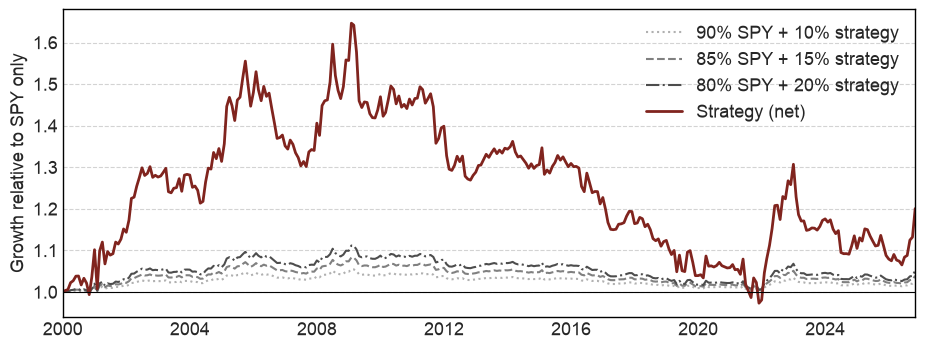

In [162]:
def plot_relative_wealth(rets, reference, styles, name):
    """Growth of 1 of each portfolio divided by the growth of 1 of the reference portfolio."""
    wealth = wealth_index(rets)
    relative = wealth.div(wealth[reference], axis=0).drop(columns=reference)
    fig, ax = plt.subplots(figsize=(11, 4))
    for column in relative:
        ax.plot(relative.index, relative[column], label=column, **styles[column])
    ax.axhline(1, color="black", linewidth=0.8)
    ax.margins(x=0)
    ax.set_ylabel("Growth relative to SPY only")
    ax.legend(frameon=False, loc="upper right")
    style_axes(ax)
    save_figure(fig, name)
    plt.show()


blend_styles = {
    label: dict(color=shade, linestyle=line, linewidth=1.5)
    for label, shade, line in zip(blend_returns.columns[1:], ["#B0B0B0", "#808080", "#4D4D4D"], [":", "--", "-."])
}
blend_styles[NET] = STYLES[NET]
blend_returns[NET] = monthly[NET]

print("Figure 7: growth of each portfolio relative to SPY alone")
plot_relative_wealth(blend_returns, "SPY only", blend_styles, "fig7_blend")

#### 9. Limitations checks

The first two checks test the construction of the backtest. The last one describes how concentrated
and how active the strategy is.

1. **No look-ahead:** the weights at a month-end are recomputed using only the prices up to that month-end
   and must equal the weights of the full-sample run.
2. **Valid portfolios:** in every month the weights sum to 1 and exactly `N_HOLD` ETFs are held.
3. **Concentration and holding period:** how often each ETF is held and how long a holding lasts (Table 8 and Figure 8).

In [163]:
live = weights.dropna(how="all")

test_dates = live.index[::12]
for date in test_dates:
    truncated = top_n_weights(momentum_signal(prices[SECTORS].loc[:date], LOOKBACK, SKIP), N_HOLD)
    assert truncated.loc[date].equals(weights.loc[date]), f"weights at {date:%Y-%m} use future prices"
print(f"No look-ahead: weights match when the data stops at each of {len(test_dates)} test dates")

assert np.allclose(live.sum(axis=1), 1), "weights do not sum to 1"
assert (live.gt(0).sum(axis=1) == N_HOLD).all(), "wrong number of holdings"
print(f"Valid portfolios: weights sum to 1 and {N_HOLD} ETFs are held in all {len(live)} months")

No look-ahead: weights match when the data stops at each of 27 test dates
Valid portfolios: weights sum to 1 and 3 ETFs are held in all 323 months


In [164]:
def holding_spells(flags):
    """Start date and length in months of every consecutive spell in which an ETF is held."""
    spell_id = (flags != flags.shift()).cumsum()
    spells = flags.groupby(spell_id).agg(start=lambda s: s.index[0], months="size", held="first")
    return spells.loc[spells["held"], ["start", "months"]]


held = weights.shift(1).dropna(how="all").gt(0)
in_universe = signal.notna().shift(1, fill_value=False).loc[held.index]
spells = {ticker: holding_spells(held[ticker]) for ticker in held}
changes = held.astype(int).diff().abs().sum(axis=1).iloc[1:]

print("Table 8: how often and how long each ETF is held")
table7 = pd.DataFrame({
    "name": pd.Series(SECTOR_NAMES),
    "months in ranking": in_universe.sum(),
    "months held (%)": 100 * held.sum() / in_universe.sum(),
    "average spell (months)": pd.Series({t: s["months"].mean() for t, s in spells.items()}),
    "longest spell (months)": pd.Series({t: s["months"].max() for t, s in spells.items()}),
}).sort_values("months held (%)", ascending=False)
print(f"Average holding period: {pd.concat(spells.values())['months'].mean():.1f} months")
print(f"Months in which at least one ETF is replaced: {100 * (changes > 0).mean():.0f}%")
show(table7, precision=1)

Table 8: how often and how long each ETF is held
Average holding period: 4.5 months
Months in which at least one ETF is replaced: 58%


,name,months in ranking,months held (%),average spell (months),longest spell (months)
XLC,Communication Services,88,48.9,8.6,21
XLK,Technology,322,42.2,4.9,21
XLE,Energy,322,33.5,6.0,29
XLU,Utilities,322,33.5,4.5,18
XLY,Consumer Discretionary,322,33.5,4.7,16
XLB,Materials,322,31.4,4.8,19
XLV,Health Care,322,30.1,5.7,21
XLF,Financials,322,27.3,3.4,12
XLI,Industrials,322,26.1,3.2,16
XLP,Consumer Staples,322,23.6,3.3,13


Figure 8: holdings over time


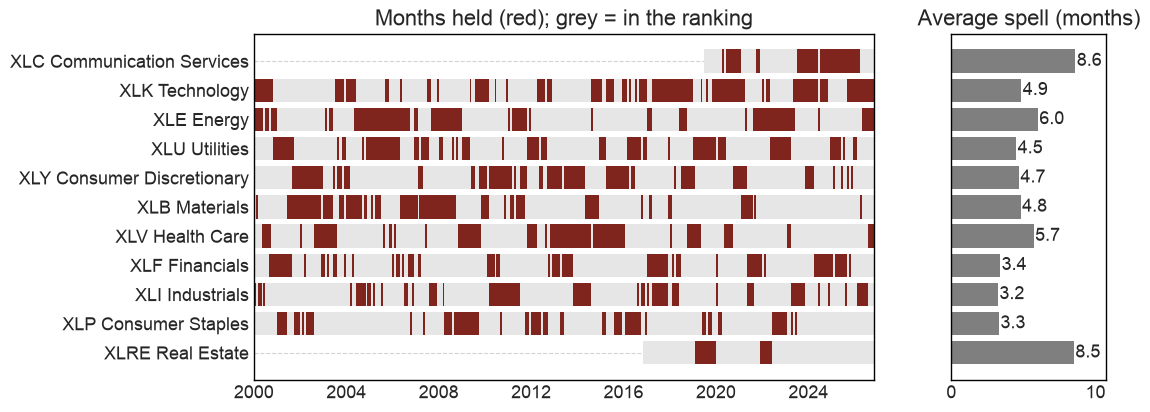

In [165]:
def plot_holdings(held, in_universe, spells, names, order, name):
    """Timeline of the months each ETF is held (left) and its average holding spell (right)."""
    month = {date: i for i, date in enumerate(held.index)}
    fig, (ax, ax_bar) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, gridspec_kw={"width_ratios": [4, 1]})
    for y, ticker in enumerate(order[::-1]):
        first = month[in_universe.index[in_universe[ticker]][0]]
        ax.broken_barh([(first, len(held) - first)], (y - 0.4, 0.8), facecolors="#E6E6E6")   # in the ranking
        ax.broken_barh([(month[s], n) for s, n in zip(spells[ticker]["start"], spells[ticker]["months"])],
                       (y - 0.4, 0.8), facecolors=ACCENT)                                     # held
        average = spells[ticker]["months"].mean()
        ax_bar.barh(y, average, height=0.8, color="#7F7F7F")
        ax_bar.text(average + 0.1, y, f"{average:.1f}", va="center")
    ticks = [i for i, date in enumerate(held.index) if date.month == 1 and date.year % 4 == 0]
    ax.set_xticks(ticks)
    ax.set_xticklabels([held.index[i].year for i in ticks])
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([f"{t} {names[t]}" for t in order[::-1]])
    ax.set_xlim(0, len(held))
    ax.set_title("Months held (red); grey = in the ranking")
    ax_bar.set_title("Average spell (months)")
    ax_bar.set_xlim(0, 1.25 * max(s["months"].mean() for s in spells.values()))
    for axis in (ax, ax_bar):
        style_axes(axis)
        axis.grid(False)
    ax.grid(axis="y", linestyle="--", color="lightgrey")
    save_figure(fig, name)
    plt.show()


print("Figure 8: holdings over time")
plot_holdings(held, in_universe, spells, SECTOR_NAMES, list(table7.index), "fig8_holdings")

**What the checks do not cover.**

- **Concentration:** three ETFs are held, each a diversified sector, but the portfolio can sit in highly
  correlated sectors and has a market beta that changes with the holdings.
- **Survivorship and universe:** the SPDR sector ETFs exist today and none was closed, so there is no
  dead ETF to miss. The universe is point-in-time (XLRE and XLC join after 12-1 months of data), but the
  sector definitions changed over time, for example when XLC was carved out in 2018.
- **Single path and data snooping:** there is one historical path. The parameters are the standard 12-1
  and three holdings, and Figure 6 shows the neighbouring settings.
- **Execution:** trades are assumed at the month-end close that produced the signal, with the cost
  levels of section 6. Real spreads and market impact are small for these liquid ETFs but not zero.
- **Taxes:** rotating monthly realizes short-term gains in a taxable account. Taxes are not modelled.
- **Scope:** US-listed ETFs in USD only, so there is no currency risk and no UCITS version.